# 05 · End to End: One Pipeline, Every Modality

Notebooks 01-04 covered MRI QC, longitudinal/anatomical comparison, MRI→histology block mapping, and digital pathology — separately. This notebook retraces all of it compactly and introduces **`integrated_utils.py`**, which chains those steps together (`summarize_mri_pathology` = one call instead of four).

In [9]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

# Ensure module path includes stroke_notebooks
for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent / "stroke_notebooks"]:
    if (p / "integrated_utils.py").exists() and str(p.resolve()) not in sys.path:
        sys.path.insert(0, str(p.resolve()))

import mri_utils as mu
import roi_utils as ru
import annotations_utils as au
from integrated_utils import (
    find_lesion_histology_sections,
    summarize_section_annotations,
    compare_lesion_annotation_density,
    summarize_mri_pathology,
    summarize_lesion_regions,
    compare_lesion_across_mri,
)

DATA_DIR = Path("data") if Path("data").is_dir() else Path("../data")
assert DATA_DIR.is_dir(), f"Dataset not found at {DATA_DIR}"

# --- Reusable Display & Plotting Helpers ---
def table_view(df, cols, head=None):
    """Display compact DataFrame with only essential interpretation columns."""
    sub = df[cols]
    return sub.head(head) if head else sub

def plot_mri_slices(mri, mask, center=(219, 126, 88)):
    """Orthogonal multiplanar slices of MRI background with lesion mask overlay."""
    i, j, k = center
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
    planes = [
        ('Sagittal', mri.data[i, :, :].T, mask[i, :, :].T),
        ('Coronal', mri.data[:, j, :].T, mask[:, j, :].T),
        ('Axial', mri.data[:, :, k].T, mask[:, :, k].T),
    ]
    for ax, (title, img, m) in zip(axes, planes):
        ax.imshow(img, cmap='gray', origin='lower')
        if np.any(m):
            ax.contour(m, colors='red', linewidths=1.2)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    fig.suptitle('Ischemic Core (Red Outline) on DWI', fontsize=11)
    plt.tight_layout()
    return fig

def plot_longitudinal_slices(mri_a, mri_b, mask_a, mask_b, k_slice=88):
    """Side-by-side axial comparison of acute vs subacute lesion footprint."""
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
    axes[0].imshow(mri_a.data[:, :, k_slice].T, cmap='gray', origin='lower')
    axes[0].contour(mask_a[:, :, k_slice].T, colors='cyan', linewidths=1.2)
    axes[0].set_title('16 dpm Acute (Cyan)', fontsize=10)
    axes[0].axis('off')

    axes[1].imshow(mri_b.data[:, :, k_slice].T, cmap='gray', origin='lower')
    axes[1].contour(mask_b[:, :, k_slice].T, colors='red', linewidths=1.2)
    axes[1].set_title('11 dpm Subacute (Red)', fontsize=10)
    axes[1].axis('off')

    fig.suptitle('Longitudinal Core Contraction (Axial k=88)', fontsize=11)
    plt.tight_layout()
    return fig

# --- Dataset & Manifest Sanity Check ---
manifest = mu.load_manifest(DATA_DIR / "manifest.json")
sanity_df = pd.DataFrame([{
    "reference_grid": " x ".join(map(str, manifest["space"]["dims"])),
    "voxel_spacing_mm": " x ".join(f"{s:.2f}" for s in manifest["space"]["spacing"]),
    "n_blocks": len(manifest["blocks"]),
    "block_ids": ", ".join(manifest["blocks"].keys()),
}])
print("✓ Manifest & Grid Geometry Sanity Check:")
display(sanity_df)


✓ Manifest & Grid Geometry Sanity Check:


,reference_grid,voxel_spacing_mm,n_blocks,block_ids
0,211 x 377 x 238,0.49 x 0.49 x 0.70,5,"218, 217, 313, 315, 314"


## 1. Ischemic Core (≈ Notebook 01)

Same dual-modality rule as notebook 01: $DWI \ge 150$ and $ADC \le 750$ (ADC excludes T2 shine-through).

,volume_shape,voxel_spacing_mm,core_voxels,core_volume_mL,pct_brain
0,"(377, 211, 238)",0.49 x 0.49 x 0.70,488482,81.52,9.53


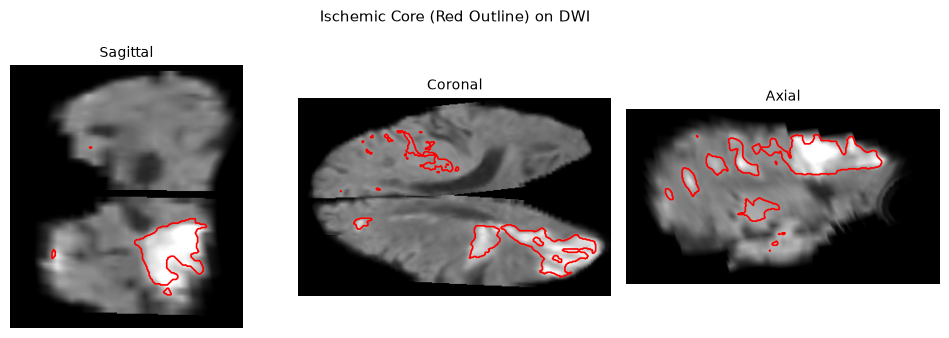

In [10]:
# Load diffusion pair and segment acute ischemic core
pair11 = mu.load_diffusion_pair(DATA_DIR / "iv11_DWI.nii.gz", DATA_DIR / "iv11_ADC.nii.gz")
core11 = mu.restricted_diffusion_lesion(pair11, dwi_threshold=150.0, adc_max=750.0)

vx_ml = np.prod(pair11.dwi.voxel_mm) / 1000.0
lesion_metrics = pd.DataFrame([{
    "volume_shape": str(pair11.shape),
    "voxel_spacing_mm": " x ".join(f"{v:.2f}" for v in pair11.dwi.voxel_mm),
    "core_voxels": int(core11.sum()),
    "core_volume_mL": round(float(core11.sum()) * vx_ml, 2),
    "pct_brain": round(100.0 * float(core11.sum()) / float(pair11.brain_mask.sum()), 2),
}])
display(lesion_metrics)

# Vis 1: Multiplanar orthogonal inspection of core delineation
fig_mri = plot_mri_slices(pair11.dwi, core11)
plt.show()


## 2. Anatomy & Arteries (≈ Notebook 02)

`summarize_lesion_regions(core_mask, manifest, atlas="both", lr_swap=True)` runs the MNI + arterial lookups in one call instead of two.

In [11]:
# Regional lesion burden breakdown (MNI & Arterial)
region_breakdown = summarize_lesion_regions(core11, manifest, atlas="both", lr_swap=True, top_n=5)
cols_reg = ["name", "region_volume_mL", "lesion_volume_mL", "pct_region_infiltrated"]

print("Top Anatomical Regions (MNI):")
display(table_view(region_breakdown["anatomical"], cols_reg, head=5))

print("\nTop Arterial Supply Territories:")
display(table_view(region_breakdown["arterial"], cols_reg, head=5))


Top Anatomical Regions (MNI):


,name,region_volume_mL,lesion_volume_mL,pct_region_infiltrated
0,white matter of forebrain,365.92,32.23,8.81
1,inferior occipital gyrus,38.35,10.02,26.14
2,superior occipital gyrus,27.86,7.34,26.33
3,putamen,11.97,5.88,49.09
4,supraparietal lobule,19.00,4.64,24.44



Top Arterial Supply Territories:


,name,region_volume_mL,lesion_volume_mL,pct_region_infiltrated
0,occipital pars of middle cerebral artery left,57.44,17.03,29.64
1,parietal pars of middle cerebral artery left,77.00,13.55,17.59
2,anterior cerebral artery left,95.75,10.95,11.44
3,occipital pars of posterior cerebral artery left,62.05,9.29,14.97
4,frontal pars of middle cerebral artery left,103.86,7.66,7.37


## 3. Longitudinal Change (≈ Notebook 02)

*Needs co-registered scans* (`check_spatial_alignment`, notebook 01 §2.1) — that's what makes this comparison valid.

,volume_mL_16dpm,volume_mL_11dpm,volume_change_mL,pct_volume_change,dice_overlap
0,161.66,81.52,-80.13,-49.57,0.204


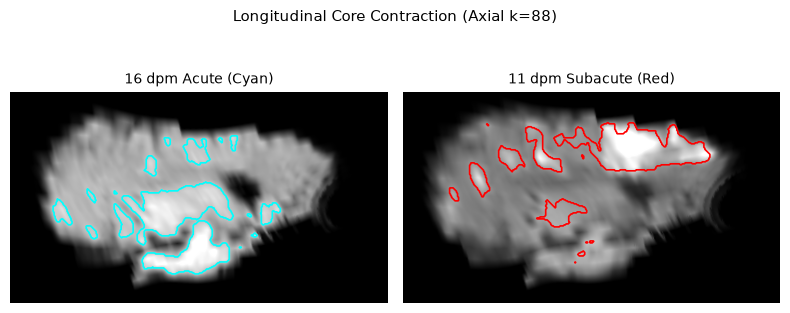

In [12]:
iv16 = mu.load_mri(DATA_DIR / "iv16_DWI.nii.gz")
mask16 = mu.lesion_mask(iv16, mu.brain_mask(iv16), threshold=150.0, verbose=False)

long_df = compare_lesion_across_mri(iv16, pair11.dwi, mask_a=mask16, mask_b=core11, label_a="16dpm", label_b="11dpm")
cols_long = ["volume_mL_16dpm", "volume_mL_11dpm", "volume_change_mL", "pct_volume_change", "dice_overlap"]
display(table_view(long_df, cols_long))

# Vis 2: Comparative axial slice showing lesion contraction (edema resolution)
fig_long = plot_longitudinal_slices(iv16, pair11.dwi, mask16, core11)
plt.show()


## 4. MRI → Histology Block (≈ Notebook 03)

Uses the `krow` cutting transform from `manifest.json` via `find_lesion_histology_sections`. Resolves *which section to pull* only — not 2D in-plane registration (notebook 03 §3.4).

In [13]:
blocks_df = find_lesion_histology_sections(core11, manifest)
cols_blk = ["block_id", "block_n", "voxel_fraction", "section_range", "mm_span"]
display(table_view(blocks_df, cols_blk))

top_blk = int(blocks_df.iloc[0]["block_id"])
print(f"Primary candidate: Block {top_blk} ({blocks_df.iloc[0]['voxel_fraction']*100:.1f}% of core voxels, span: {blocks_df.iloc[0]['section_range']}).")


,block_id,block_n,voxel_fraction,section_range,mm_span
0,313,3,0.4659,24–1842,36.35
1,315,4,0.2022,147–986,16.80
2,217,2,0.1556,94–1805,34.21
3,314,5,0.1196,145–1156,20.21
4,218,1,0.0567,202–1955,35.05


Primary candidate: Block 313 (46.6% of core voxels, span: 24–1842).


## 5. Are Those Sections Annotated? (Bridge into Notebook 04)

`summarize_section_annotations(sections, biosample_id, stain)` — cheap check of which candidate sections are worth loading, before downloading any pixels.

In [14]:
# Query verified physical sections from Block 313 histology register
candidate_secs = [1031, 1079, 1145, 1193, 1271]
annot_df = summarize_section_annotations(candidate_secs, biosample_id=top_blk, stain="IHCS")
cols_ann = ["section", "stain", "proteins", "has_annotations"]
display(table_view(annot_df, cols_ann))


,section,stain,proteins,has_annotations
0,1031,IHCS,"GFAP, GAP43",True
1,1079,IHCS,"GFAP, GAP43",True
2,1145,IHCS,CD68,True
3,1193,IHCS,GFAP,True
4,1271,IHCS,FIB,True


## 6. Pathology in the ROI (≈ Notebook 04)

Reuses the same 117-section ROI stack from notebook 04. `create_annotation_overlay` draws the stain on tissue; `compare_lesion_annotation_density` asks whether annotation density differs *inside* vs. *outside* the MRI lesion's cutting range.

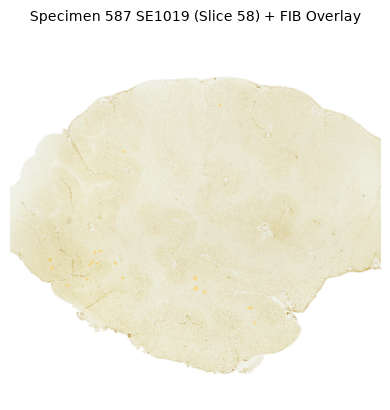

,protein,inside_mean_area,density_ratio,association
0,FIB,404.92,inf,Present only in lesion range


In [15]:
# 1. Load real ROI stack (local cache or Drive ID)
ROI_DRIVE_ID = "1L1_QprfzYrT8v_hhj8LXJJCRq9duIrbQ"
roi_path = DATA_DIR / "ROI_587_SE1019_X12000_Y12000_Z117_768x768_L4_axial_IHCS.npy"

if roi_path.exists():
    roi = ru.load_roi(roi_path)
    roi_meta = {"filename": roi_path.name, "center_section": 1019, "stain": "IHCS"}
else:
    roi, roi_meta = ru.load_and_preview_roi(ROI_DRIVE_ID, preview=False, return_meta=True)

# 2. Query annotations for slice 58 (Atlas SE 1019)
roi_ann = au.load_roi_annotations(roi, roi_meta, biosample_id=587, stain="IHCS", section_indices=[58], verbose=False)

# Vis 3: Stained tissue with molecular pathology (FIB) annotation overlay
overlay = au.create_annotation_overlay(roi, roi_ann, section_index=58)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(overlay)
ax.set_title('Specimen 587 SE1019 (Slice 58) + FIB Overlay', fontsize=10)
ax.axis('off')
plt.tight_layout()
plt.show()

# 3. Density comparison across Block 218 cutting range
b218_range = (int(blocks_df.loc[blocks_df["block_id"] == 218, "section_min"].iloc[0]),
              int(blocks_df.loc[blocks_df["block_id"] == 218, "section_max"].iloc[0]))
density_df = compare_lesion_annotation_density(roi_ann, lesion_section_range=b218_range)
cols_den = ["protein", "inside_mean_area", "density_ratio", "association"]
display(table_view(density_df, cols_den))


## 7. One Call for All of It

`summarize_mri_pathology(core_mask, manifest, roi_stack, roi_meta, block_id, stain)` runs steps 4-6 as a single bundle. If a step you need isn't in this bundle, that's a gap worth raising for `integrated_utils.py`.

In [17]:
# 1. Orchestrated multi-modal execution
bundle = summarize_mri_pathology(core11, manifest, roi_stack=roi, roi_meta=roi_meta, block_id=218, stain="IHCS")
print(f"Orchestration Target Block: {bundle['primary_block_id']} | Range: {bundle['primary_section_range']}")
cols_bundle = ["protein", "inside_mean_area", "inside_annotated_sections", "density_ratio", "association"]
display(table_view(bundle["density_comparison"], cols_bundle))


Orchestration Target Block: 218 | Range: (202, 1955)


,protein,inside_mean_area,inside_annotated_sections,density_ratio,association
0,CD34,126682.80,22,inf,Present only in lesion range
1,CD68,94746.02,18,inf,Present only in lesion range
2,FIB,5699.02,16,inf,Present only in lesion range
3,GFAP,108634.77,18,inf,Present only in lesion range
4,HIF1a,69685.48,11,inf,Present only in lesion range
